# Deteccion de DDoS con LSTM y GRU

Este notebook usa el dataset local en formato `.parquet` y lo transforma en **secuencias temporales aproximadas** para comparar dos modelos recurrentes:

- **LSTM**
- **GRU**

El dataset original esta en formato tabular por flujo de red. Como no conserva columnas de tiempo/IP/Flow ID, se crean ventanas consecutivas dentro de cada archivo `.parquet`. Esta aproximacion permite evaluar patrones secuenciales usando las caracteristicas de flujo como `Flow Duration`, `Flow IAT`, `Active` e `Idle`.

## 1. Importar librerias

Si TensorFlow no esta instalado, ejecutar primero:

```bash
pip install tensorflow scikit-learn pandas pyarrow matplotlib seaborn
```

In [1]:
from pathlib import Path
import json
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow:', tf.__version__)

TensorFlow: 2.19.0


## 2. Configuracion del experimento

Para evitar problemas de memoria RAM, el notebook no carga todo sin control. Puedes ajustar:

- `MAX_ROWS_PER_FILE`: maximo de filas por archivo.
- `TIMESTEPS`: cantidad de registros por secuencia.
- `STRIDE`: salto entre ventanas. Mayor valor consume menos memoria.
- `EPOCHS`: epocas de entrenamiento.

In [2]:
DATA_DIR = Path('archive')
OUTPUT_DIR = Path('modelos_lstm_gru')
OUTPUT_DIR.mkdir(exist_ok=True)

TIMESTEPS = 10
STRIDE = 2
MAX_ROWS_PER_FILE = 12000
EPOCHS = 12
BATCH_SIZE = 128
VALIDATION_SPLIT = 0.2

print('Dataset:', DATA_DIR.resolve())
print('Salida:', OUTPUT_DIR.resolve())

Dataset: /Users/adonisalegria/Documents/Universidad/Seguridad/Proyecto/PRUEBA3/LSTMDDOS/archive
Salida: /Users/adonisalegria/Documents/Universidad/Seguridad/Proyecto/PRUEBA3/LSTMDDOS/modelos_lstm_gru


## 3. Revisar archivos disponibles

In [3]:
parquet_files = sorted(DATA_DIR.glob('*.parquet'))
print('Archivos encontrados:', len(parquet_files))

summary = []
for file in parquet_files:
    df_temp = pd.read_parquet(file, columns=['Label'])
    summary.append({
        'archivo': file.name,
        'filas': len(df_temp),
        'labels': ', '.join(map(str, sorted(df_temp['Label'].astype(str).unique())[:6]))
    })

pd.DataFrame(summary)

Archivos encontrados: 17


,archivo,filas,labels
0,DNS-testing.parquet,6703,"Benign, DrDoS_DNS"
1,LDAP-testing.parquet,2831,"Benign, DrDoS_LDAP"
2,LDAP-training.parquet,6715,"Benign, LDAP, NetBIOS"
3,MSSQL-testing.parquet,8083,"Benign, DrDoS_MSSQL"
4,MSSQL-training.parquet,10974,"Benign, LDAP, MSSQL"
5,NTP-testing.parquet,134674,"Benign, DrDoS_NTP"
6,NetBIOS-testing.parquet,2225,"Benign, DrDoS_NetBIOS"
7,NetBIOS-training.parquet,1631,"Benign, NetBIOS"
8,Portmap-training.parquet,5105,"Benign, Portmap"
9,SNMP-testing.parquet,4018,"Benign, DrDoS_SNMP"


## 4. Cargar datos tabulares

Se separan los archivos `*-training.parquet` para entrenamiento y `*-testing.parquet` para prueba. La etiqueta se convierte a binaria:

- `0`: Benign
- `1`: Ataque DDoS

In [4]:
def load_split(split_name, max_rows_per_file=MAX_ROWS_PER_FILE):
    files = sorted(DATA_DIR.glob(f'*-{split_name}.parquet'))
    if not files:
        raise FileNotFoundError(f'No se encontraron archivos para split: {split_name}')

    frames = []
    for file in files:
        df = pd.read_parquet(file)
        if max_rows_per_file and len(df) > max_rows_per_file:
            df = df.sample(n=max_rows_per_file, random_state=SEED).sort_index()
        df['source_file'] = file.name
        frames.append(df)
        print(f'{file.name:24s} -> {len(df):7d} filas')

    return pd.concat(frames, ignore_index=True)

train_df = load_split('training')
test_df = load_split('testing')

print('\nTrain:', train_df.shape)
print('Test :', test_df.shape)

LDAP-training.parquet    ->    6715 filas
MSSQL-training.parquet   ->   10974 filas
NetBIOS-training.parquet ->    1631 filas
Portmap-training.parquet ->    5105 filas
Syn-training.parquet     ->   12000 filas
UDP-training.parquet     ->   12000 filas
UDPLag-training.parquet  ->   12000 filas
DNS-testing.parquet      ->    6703 filas
LDAP-testing.parquet     ->    2831 filas
MSSQL-testing.parquet    ->    8083 filas
NTP-testing.parquet      ->   12000 filas
NetBIOS-testing.parquet  ->    2225 filas
SNMP-testing.parquet     ->    4018 filas
Syn-testing.parquet      ->     907 filas
TFTP-testing.parquet     ->   12000 filas
UDP-testing.parquet      ->   12000 filas
UDPLag-testing.parquet   ->   12000 filas

Train: (60425, 79)
Test : (72767, 79)


In [5]:
def prepare_binary_labels(df):
    labels = df['Label'].astype(str).str.lower().str.strip()
    return (labels != 'benign').astype('int32')

feature_cols = [c for c in train_df.columns if c not in ['Label', 'source_file']]

X_train_raw = train_df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
X_test_raw = test_df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)

y_train_raw = prepare_binary_labels(train_df)
y_test_raw = prepare_binary_labels(test_df)

print('Caracteristicas:', len(feature_cols))
print('Train labels:')
print(y_train_raw.value_counts().rename(index={0:'Benign', 1:'Ataque'}))
print('\nTest labels:')
print(y_test_raw.value_counts().rename(index={0:'Benign', 1:'Ataque'}))

Caracteristicas: 77
Train labels:
Label
Ataque    37550
Benign    22875
Name: count, dtype: int64

Test labels:
Label
Ataque    54331
Benign    18436
Name: count, dtype: int64


## 5. Escalar caracteristicas

El escalador se ajusta solo con el entrenamiento para evitar fuga de informacion hacia testing.

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw).astype('float32')
X_test_scaled = scaler.transform(X_test_raw).astype('float32')

y_train_values = y_train_raw.to_numpy(dtype='int32')
y_test_values = y_test_raw.to_numpy(dtype='int32')

print('X_train_scaled:', X_train_scaled.shape)
print('X_test_scaled :', X_test_scaled.shape)

X_train_scaled: (60425, 77)
X_test_scaled : (72767, 77)


## 6. Crear secuencias para LSTM/GRU

Cada secuencia contiene `TIMESTEPS` filas consecutivas. La etiqueta de la secuencia se toma de la ultima fila de la ventana.

Ejemplo con `TIMESTEPS = 10`:

```text
[fila 1 ... fila 10] -> etiqueta de fila 10
[fila 3 ... fila 12] -> etiqueta de fila 12   si STRIDE = 2
```

In [7]:
def make_sequences_by_file(X_scaled, y_values, source_files, timesteps=TIMESTEPS, stride=STRIDE):
    X_seq_parts = []
    y_seq_parts = []

    source_files = np.asarray(source_files)
    for file_name in pd.unique(source_files):
        idx = np.where(source_files == file_name)[0]
        if len(idx) < timesteps:
            continue

        X_file = X_scaled[idx]
        y_file = y_values[idx]

        windows = []
        labels = []
        for start in range(0, len(X_file) - timesteps + 1, stride):
            end = start + timesteps
            windows.append(X_file[start:end])
            labels.append(y_file[end - 1])

        if windows:
            X_seq_parts.append(np.asarray(windows, dtype='float32'))
            y_seq_parts.append(np.asarray(labels, dtype='int32'))
            print(f'{file_name:24s} -> {len(windows):7d} secuencias')

    X_seq = np.concatenate(X_seq_parts, axis=0)
    y_seq = np.concatenate(y_seq_parts, axis=0)
    return X_seq, y_seq

X_train_seq, y_train_seq = make_sequences_by_file(
    X_train_scaled,
    y_train_values,
    train_df['source_file'].to_numpy(),
)

X_test_seq, y_test_seq = make_sequences_by_file(
    X_test_scaled,
    y_test_values,
    test_df['source_file'].to_numpy(),
)

print('\nX_train_seq:', X_train_seq.shape)
print('y_train_seq:', y_train_seq.shape)
print('X_test_seq :', X_test_seq.shape)
print('y_test_seq :', y_test_seq.shape)

LDAP-training.parquet    ->    3353 secuencias
MSSQL-training.parquet   ->    5483 secuencias
NetBIOS-training.parquet ->     811 secuencias
Portmap-training.parquet ->    2548 secuencias
Syn-training.parquet     ->    5996 secuencias
UDP-training.parquet     ->    5996 secuencias
UDPLag-training.parquet  ->    5996 secuencias
DNS-testing.parquet      ->    3347 secuencias
LDAP-testing.parquet     ->    1411 secuencias
MSSQL-testing.parquet    ->    4037 secuencias
NTP-testing.parquet      ->    5996 secuencias
NetBIOS-testing.parquet  ->    1108 secuencias
SNMP-testing.parquet     ->    2005 secuencias
Syn-testing.parquet      ->     449 secuencias
TFTP-testing.parquet     ->    5996 secuencias
UDP-testing.parquet      ->    5996 secuencias
UDPLag-testing.parquet   ->    5996 secuencias

X_train_seq: (30183, 10, 77)
y_train_seq: (30183,)
X_test_seq : (36341, 10, 77)
y_test_seq : (36341,)


## 7. Funciones para crear, entrenar y evaluar modelos

In [8]:
input_shape = (X_train_seq.shape[1], X_train_seq.shape[2])

classes = np.unique(y_train_seq)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_seq)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}
print('input_shape:', input_shape)
print('class_weight:', class_weight)


def build_lstm_model(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Masking(mask_value=0.0),
        layers.LSTM(64, return_sequences=False),
        layers.Dropout(0.30),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.20),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
    )
    return model


def build_gru_model(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Masking(mask_value=0.0),
        layers.GRU(64, return_sequences=False),
        layers.Dropout(0.30),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.20),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
    )
    return model


def train_model(model, name):
    print(f'\nEntrenando {name}...')
    cb = [
        callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
        callbacks.ModelCheckpoint(OUTPUT_DIR / f'{name}.keras', monitor='val_loss', save_best_only=True)
    ]
    history = model.fit(
        X_train_seq,
        y_train_seq,
        validation_split=VALIDATION_SPLIT,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight,
        callbacks=cb,
        verbose=1
    )
    return history


def evaluate_model(model, name):
    probs = model.predict(X_test_seq, batch_size=BATCH_SIZE).ravel()
    preds = (probs >= 0.5).astype('int32')

    metrics = {
        'modelo': name,
        'accuracy': accuracy_score(y_test_seq, preds),
        'precision': precision_score(y_test_seq, preds, zero_division=0),
        'recall': recall_score(y_test_seq, preds, zero_division=0),
        'f1_score': f1_score(y_test_seq, preds, zero_division=0),
    }

    print(f'\n{name}')
    print(classification_report(y_test_seq, preds, target_names=['Benign', 'Ataque'], zero_division=0))
    return metrics, preds, probs

input_shape: (10, 77)
class_weight: {0: 1.319533094342922, 1: 0.8050517443721327}


## 8. Entrenar LSTM

In [9]:
lstm_model = build_lstm_model(input_shape)
lstm_model.summary()
lstm_history = train_model(lstm_model, 'modelo_lstm_ddos')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 10, 77)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        36,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,465 (150.25 KB)

 Trainable params: 38,465 (150.25 KB)

 Non-trainable params: 0 (0.00 B)


Entrenando modelo_lstm_ddos...
Epoch 1/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9921 - loss: 0.0512 - precision: 0.9907 - recall: 0.9962 - val_accuracy: 0.9998 - val_loss: 0.0104 - val_precision: 0.9998 - val_recall: 1.0000
Epoch 2/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9995 - loss: 0.0030 - precision: 0.9993 - recall: 0.9999 - val_accuracy: 0.9997 - val_loss: 0.0063 - val_precision: 0.9995 - val_recall: 1.0000
Epoch 3/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9998 - loss: 0.0017 - precision: 0.9997 - recall: 1.0000 - val_accuracy: 0.9997 - val_loss: 0.0036 - val_precision: 0.9995 - val_recall: 1.0000
Epoch 4/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9999 - loss: 7.8178e-04 - precision: 0.9998 - recall: 1.0000 - val_accuracy: 0.9997 - val_loss: 0.0028 - val_precision: 0.9995 - val_recall: 1.0000
Epoch 5/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 3.0479e-04 - precision: 0.9999 - recall: 1.00

## 9. Entrenar GRU

In [10]:
gru_model = build_gru_model(input_shape)
gru_model.summary()
gru_history = train_model(gru_model, 'modelo_gru_ddos')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking_1 (Masking)             │ (None, 10, 77)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        27,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,569 (115.50 KB)

 Trainable params: 29,569 (115.50 KB)

 Non-trainable params: 0 (0.00 B)


Entrenando modelo_gru_ddos...
Epoch 1/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9860 - loss: 0.0627 - precision: 0.9845 - recall: 0.9924 - val_accuracy: 0.9998 - val_loss: 0.0052 - val_precision: 0.9998 - val_recall: 1.0000
Epoch 2/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9997 - loss: 0.0025 - precision: 0.9994 - recall: 1.0000 - val_accuracy: 1.0000 - val_loss: 0.0013 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9998 - loss: 0.0010 - precision: 0.9997 - recall: 1.0000 - val_accuracy: 0.9998 - val_loss: 6.1857e-04 - val_precision: 0.9998 - val_recall: 1.0000
Epoch 4/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9999 - loss: 5.3430e-04 - precision: 0.9999 - recall: 0.9999 - val_accuracy: 0.9998 - val_loss: 6.6339e-04 - val_precision: 0.9998 - val_recall: 1.0000
Epoch 5/12
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 2.5465e-04 - precision: 1.0000 - recal

## 10. Comparar resultados

In [11]:
lstm_metrics, lstm_preds, lstm_probs = evaluate_model(lstm_model, 'LSTM')
gru_metrics, gru_preds, gru_probs = evaluate_model(gru_model, 'GRU')

results = pd.DataFrame([lstm_metrics, gru_metrics])
results

284/284 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

LSTM
              precision    recall  f1-score   support

      Benign       0.99      0.90      0.94      9196
      Ataque       0.97      1.00      0.98     27145

    accuracy                           0.97     36341
   macro avg       0.98      0.95      0.96     36341
weighted avg       0.97      0.97      0.97     36341

284/284 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

GRU
              precision    recall  f1-score   support

      Benign       0.99      0.90      0.94      9196
      Ataque       0.97      1.00      0.98     27145

    accuracy                           0.97     36341
   macro avg       0.98      0.95      0.96     36341
weighted avg       0.97      0.97      0.97     36341



,modelo,accuracy,precision,recall,f1_score
0,LSTM,0.972043,0.966639,0.996979,0.981575
1,GRU,0.970832,0.966320,0.995653,0.980767


In [12]:
results_path = OUTPUT_DIR / 'comparacion_lstm_gru.json'
results.to_json(results_path, orient='records', indent=2)
print('Resultados guardados en:', results_path)

Resultados guardados en: modelos_lstm_gru/comparacion_lstm_gru.json


## 11. Graficas de entrenamiento

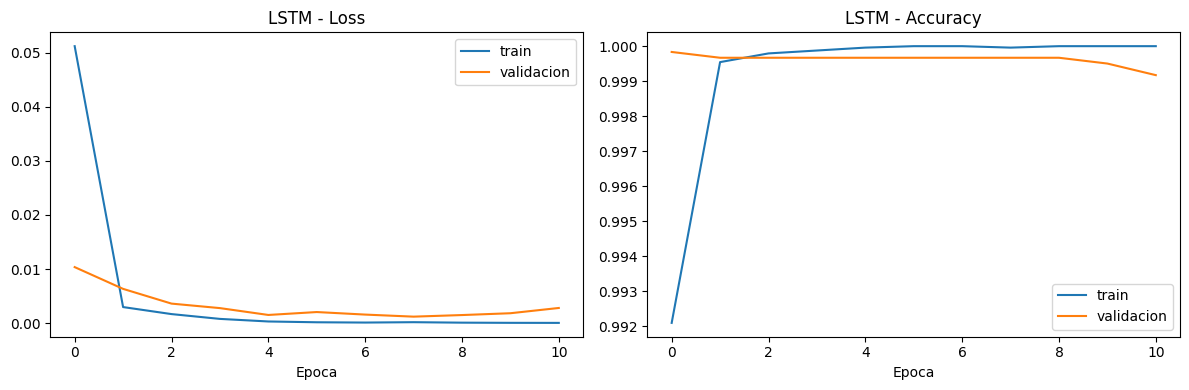

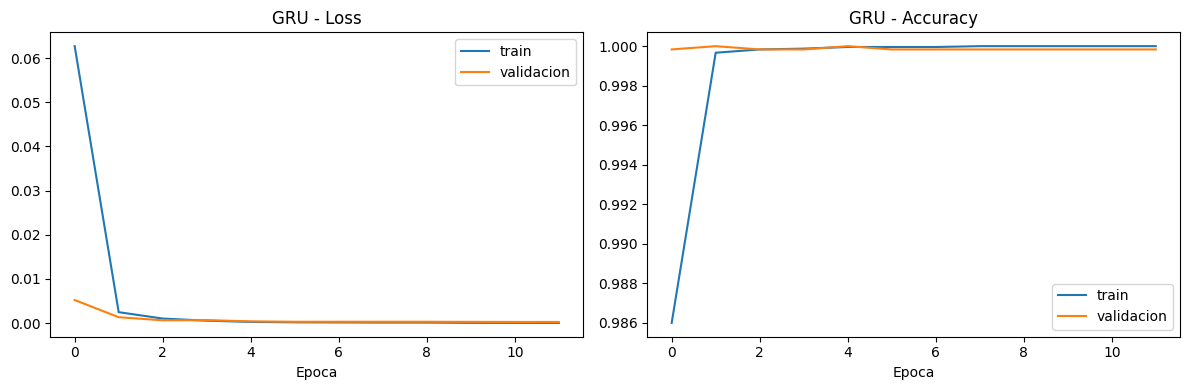

In [13]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(hist['loss'], label='train')
    axes[0].plot(hist['val_loss'], label='validacion')
    axes[0].set_title(f'{title} - Loss')
    axes[0].set_xlabel('Epoca')
    axes[0].legend()

    axes[1].plot(hist['accuracy'], label='train')
    axes[1].plot(hist['val_accuracy'], label='validacion')
    axes[1].set_title(f'{title} - Accuracy')
    axes[1].set_xlabel('Epoca')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(lstm_history, 'LSTM')
plot_history(gru_history, 'GRU')

## 12. Matrices de confusion

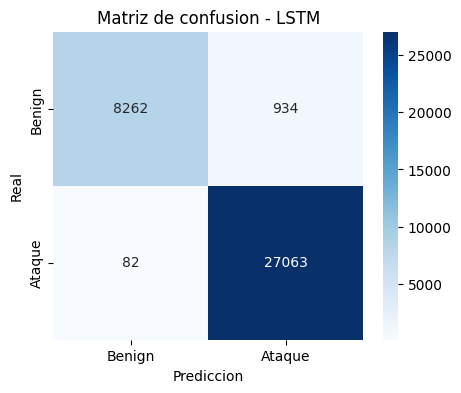

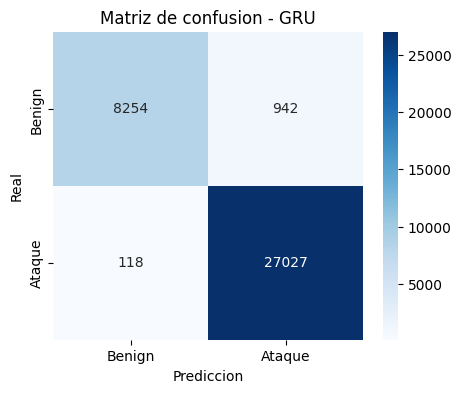

In [14]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign', 'Ataque'], yticklabels=['Benign', 'Ataque'])
    plt.title(title)
    plt.xlabel('Prediccion')
    plt.ylabel('Real')
    plt.show()

plot_confusion(y_test_seq, lstm_preds, 'Matriz de confusion - LSTM')
plot_confusion(y_test_seq, gru_preds, 'Matriz de confusion - GRU')

## 13. Guardar informacion del experimento

Se guarda la configuracion para explicar como se entrenaron los modelos.

In [15]:
experiment_info = {
    'descripcion': 'Comparativa LSTM vs GRU para deteccion binaria de DDoS usando ventanas secuenciales aproximadas.',
    'timesteps': TIMESTEPS,
    'stride': STRIDE,
    'max_rows_per_file': MAX_ROWS_PER_FILE,
    'features': feature_cols,
    'target': 'Label binaria: 0=Benign, 1=Ataque',
    'train_sequences': int(X_train_seq.shape[0]),
    'test_sequences': int(X_test_seq.shape[0]),
    'input_shape': list(input_shape),
}

info_path = OUTPUT_DIR / 'info_experimento_lstm_gru.json'
with open(info_path, 'w', encoding='utf-8') as f:
    json.dump(experiment_info, f, indent=2, ensure_ascii=False)

print('Informacion guardada en:', info_path)
print('Modelos guardados en:', OUTPUT_DIR.resolve())

Informacion guardada en: modelos_lstm_gru/info_experimento_lstm_gru.json
Modelos guardados en: /Users/adonisalegria/Documents/Universidad/Seguridad/Proyecto/PRUEBA3/LSTMDDOS/modelos_lstm_gru


## Conclusion esperada

Este notebook permite comparar si una arquitectura recurrente LSTM o GRU aprende patrones secuenciales aproximados del trafico de red. Para una explicacion academica, se debe aclarar que las secuencias se construyen a partir del orden de registros dentro de cada archivo `.parquet`, porque el dataset local no conserva timestamps ni Flow ID originales.